In [2]:
from fit_file import X_sq
import numpy as np

In [21]:
### opzetten van de fit, dataset 1 en 2
file_name1 = 'EB6_spectra_lijstenm1.txt'
freq1, amp1, phase1, dfreq1, damp1, dphase1 = np.loadtxt(file_name1, unpack = True, delimiter = ',')
for i, phase in enumerate(phase1):
    if phase > np.pi:
        phase1[i] = phase1[i] - 2 * np.pi

file_name2 = 'EB6_spectra_lijstenm2.txt'
freq2, amp2, phase2, dfreq2, damp2, dphase2 = np.loadtxt(file_name2, unpack = True, delimiter = ',')
for i, phase in enumerate(phase2):
    if phase > np.pi:
        phase1[i] = phase1[i] - 2 * np.pi


In [22]:
### modellen

def amplitude(params, freq):
    u, b, omega0 = params #u = F0/m, b = eta/m
    amp = u / (np.sqrt((omega0**2 - freq**2)**2 + (freq * b)**2))
    return amp

def faseverschil(params, freq):
    b, omega0 = params #b = eta/m
    phase = -np.arctan2(freq * b, omega0**2 - freq**2)
    return phase


---------START--------------------------------------------------------------------------------------------------


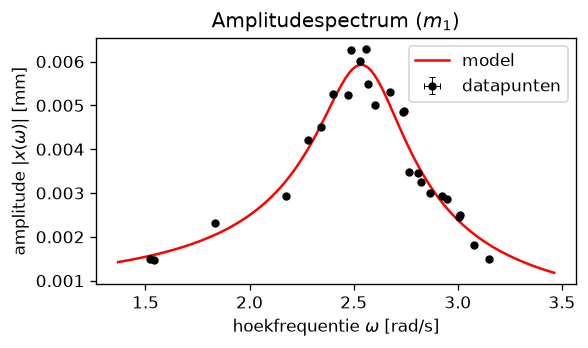

For parameter $\frac{F_0}{m}$ :     Minimum at       0.00669201     ;     68% CI = [      0.00669028,       0.00669376]
For parameter $\frac{\eta}{m}$ :     Minimum at       0.44341677     ;     68% CI = [      0.44326451,       0.44356912]
For parameter $\omega_0$ :     Minimum at       2.55563719     ;     68% CI = [      2.55547486,       2.55579952]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min      340342.02461338
Reduced χ² value       :     χ²_red       14797.47933102
P-value                :     p-value          0.00000000


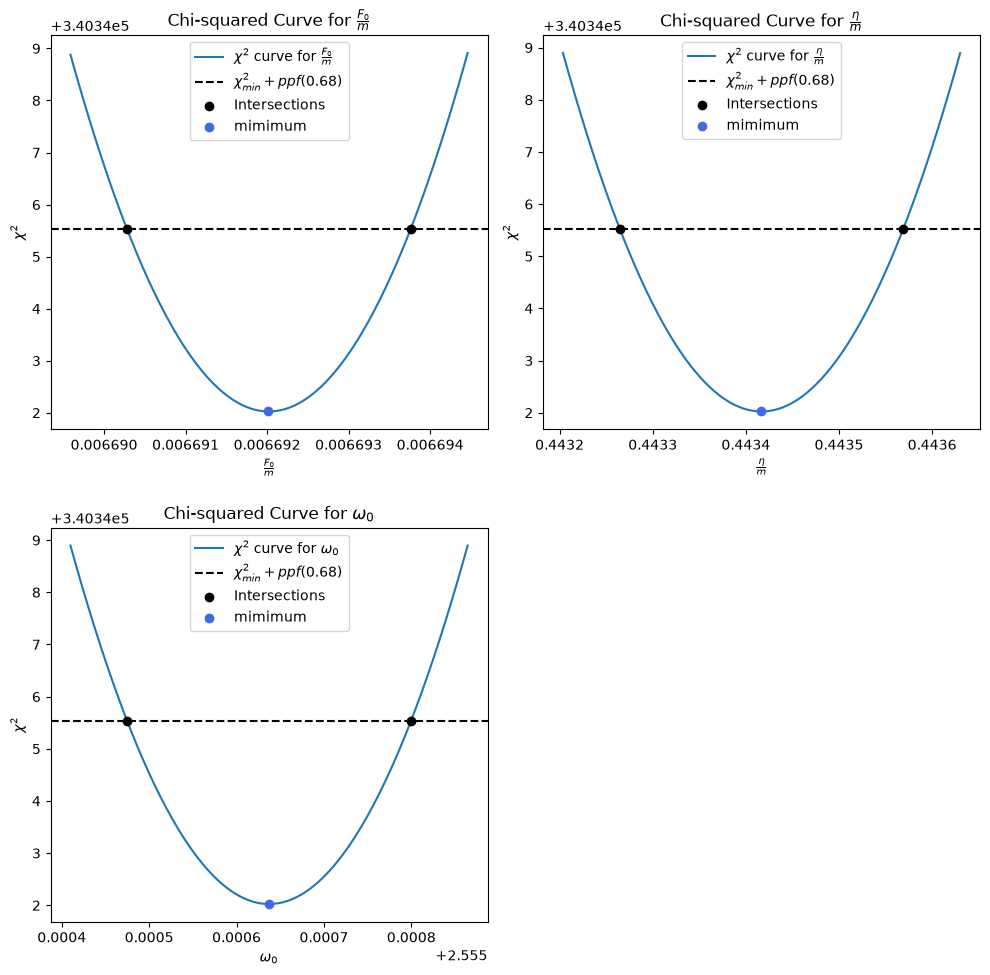

----------END---------------------------------------------------------------------------------------------------

21.566607320000003 0.10435077000000004 0.12952763999999994 0.07029722999999954 -0.07614492999999989


In [23]:
###########################################
#FITTEN DATASET 1
###########################################

###AMPLITUDE

#tampering: geen nullen in de fouten van de amplitude
#3 eerste waarden van freq weg

param_names = [r'$\frac{F_0}{m}$', r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Amplitudespectrum ($m_1$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'amplitude $|{x(\omega)}|$ [mm]'

X_sq(((freq1, dfreq1), (amp1, damp1)), param_names = param_names, initial_guess = (325.79771596, 0.75442980, 15.87811443), graf1_title = title, graf1_x_label = x_label, graf1_y_label = y_label, model = amplitude)
print(np.abs(325.79771596 - 304.23110864), np.abs(0.75442980 - 0.65007903), np.abs(0.75442980 - 0.88395744), 15.87811443 - 15.80781720, 15.87811443 - 15.95425936)


---------START--------------------------------------------------------------------------------------------------


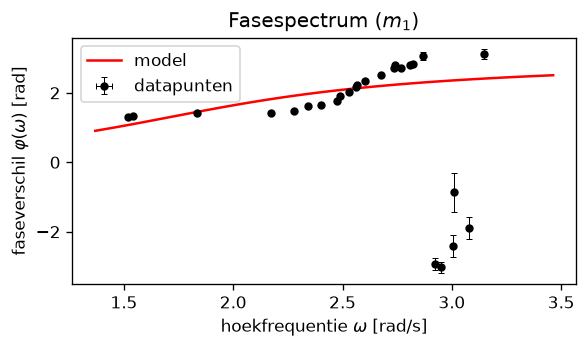

For parameter $\frac{\eta}{m}$ :     Minimum at      -1.75324854     ;     68% CI = [     -1.76884601,      -1.73785143]
For parameter $\omega_0$ :     Minimum at       1.93797548     ;     68% CI = [      1.93254617,       1.94338709]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min       18284.82947489
Reduced χ² value       :     χ²_red         761.86789479
P-value                :     p-value          0.00000000


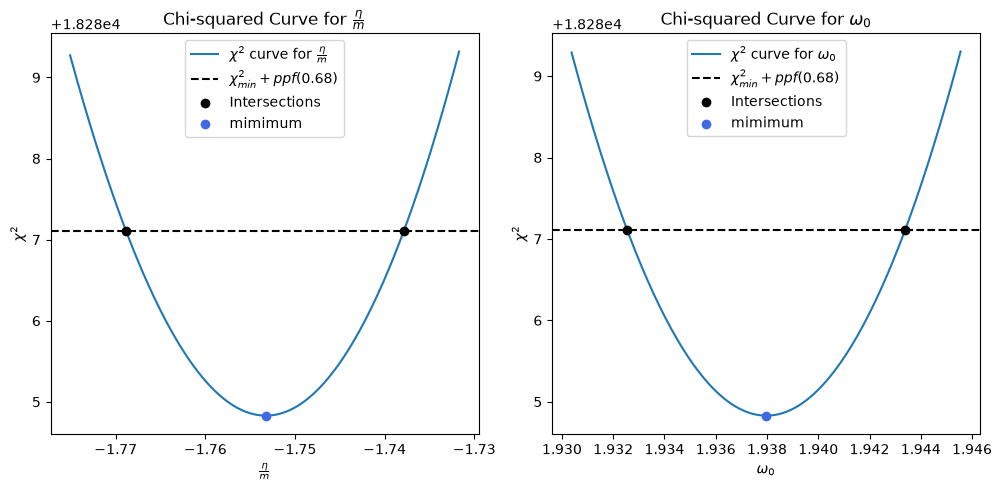

----------END---------------------------------------------------------------------------------------------------

0.13704569 -0.11972525 0.04787604999999928


In [24]:
###FASEVERSCHIL

#tampering: +np.pi voor juiste kwadrant

param_names = [r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Fasespectrum ($m_1$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'faseverschil $\varphi(\omega)$ [rad]'

X_sq(((freq1, dfreq1), (phase1, dphase1)), param_names, (0.75, 15.87), model = faseverschil, graf1_title=title, graf1_x_label = x_label, graf1_y_label = y_label)
print(-0.73780361 + 0.87484930, -0.73780361 + 0.61807836, 15.80306738 -15.75519133)


---------START--------------------------------------------------------------------------------------------------


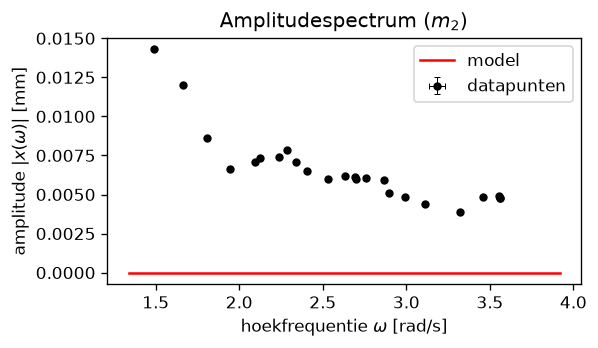

For parameter $\frac{F_0}{m}$ :     Minimum at -4429059323.23798752     ;     68% CI = [-4429089756.78307438, 4382556656765.24951172]
For parameter $\frac{\eta}{m}$ :     Failed to find root for parameter: Optimised parameter was around 766612492.69543278
For parameter $\omega_0$ :     Failed to find root for parameter: Optimised parameter was around -18198201.86732016
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min     141611943.49134558
Reduced χ² value       :     χ²_red     6743425.88054027
P-value                :     p-value          0.00000000


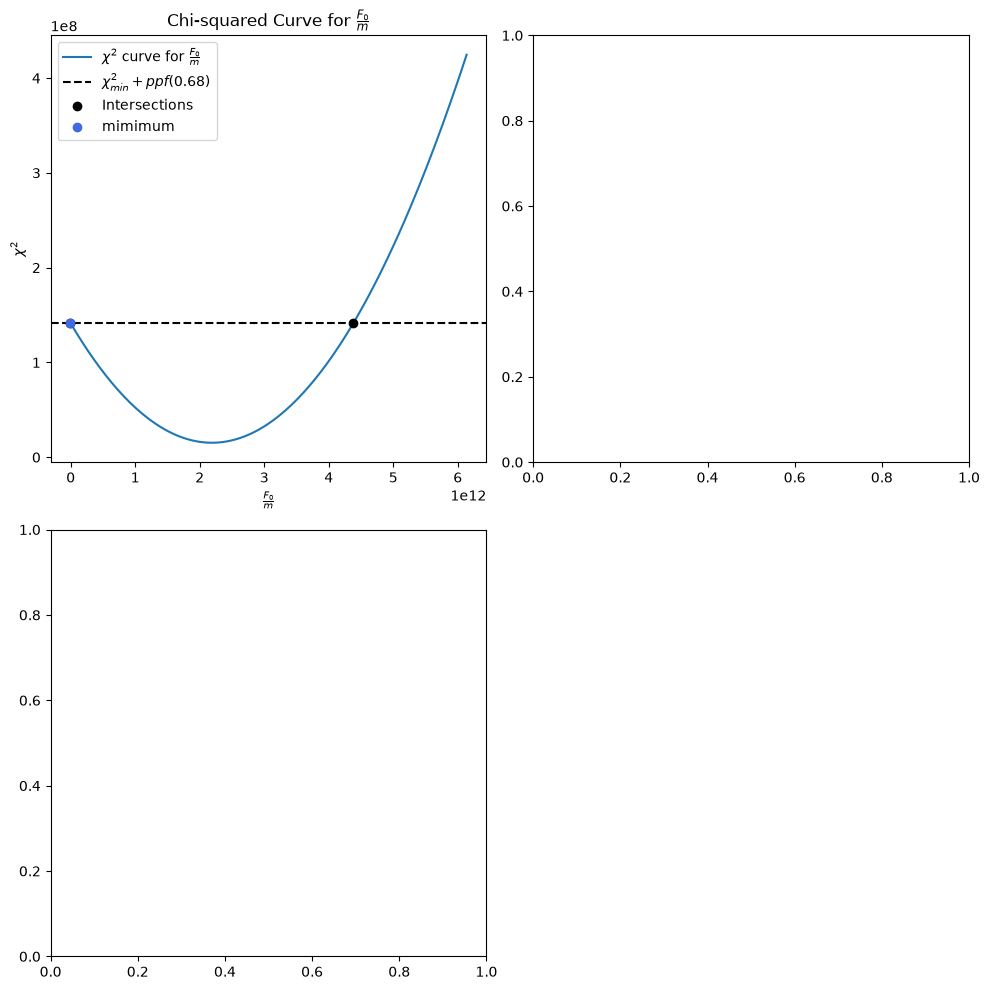

--------WARNINGS------------------------------------------------------------------------------------------------
! Roots were not found for parameter `$\frac{\eta}{m}$` after expanding the bracket. Try expanding the bracket search by using `root_attempts=1000`.
! Roots were not found for parameter `$\omega_0$` after expanding the bracket. Try expanding the bracket search by using `root_attempts=1000`.
----------END---------------------------------------------------------------------------------------------------

169.02971203000016 169.0298610599998 0.6939032100000002 0.83769736 0.4601045399999997 0.49806985000000026


In [25]:
###########################################
#FITTEN DATASET 2
###########################################

###AMPLITUDE

#tampering: geen nullen in damp2
#eerste meting weggelaten

param_names = [r'$\frac{F_0}{m}$', r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Amplitudespectrum ($m_2$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'amplitude $|{x(\omega)}|$ [mm]'

X_sq(((freq2[1:], dfreq2[1:]), (amp2[1:], damp2[1:])), param_names = param_names, initial_guess = (2429.72082953, 5.71112208, 14.99446513), graf1_title = title, graf1_x_label = x_label, graf1_y_label = y_label, model = amplitude)
print(2429.72082953-2260.69111750, 2598.75069059 - 2429.72082953, 5.71112208-5.01721887, 6.54881944-5.71112208, 14.99446513 - 14.53436059,  15.49253498 - 14.99446513)


---------START--------------------------------------------------------------------------------------------------


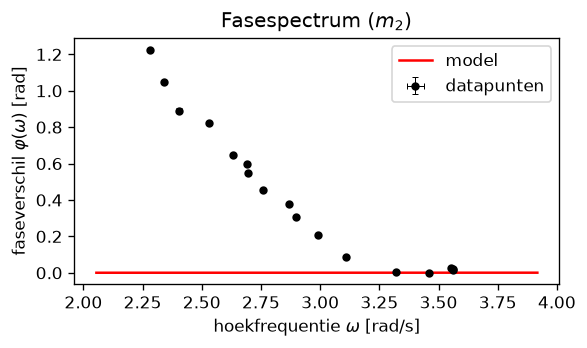

For parameter $\frac{\eta}{m}$ :     Minimum at      -2.23282920     ;     68% CI = [     -2.82170113,      -1.68566716]
For parameter $\omega_0$ :     Minimum at     121.16397476     ;     68% CI = [    107.81366499,     139.45939561]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min       73420.48370761
Reduced χ² value       :     χ²_red        4894.69891384
P-value                :     p-value          0.00000000


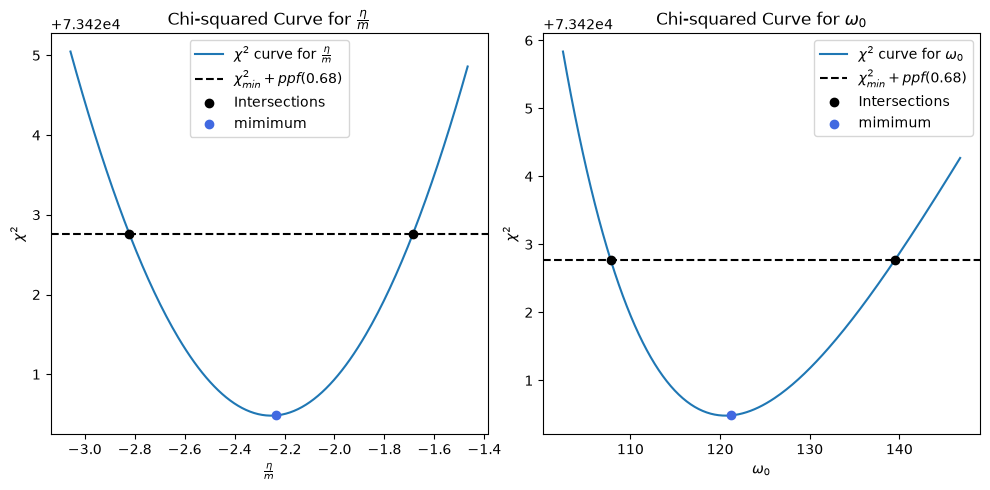

----------END---------------------------------------------------------------------------------------------------

0.3299745700000001 -0.31930460999999966 0.2081417400000003 0.21962798999999933


In [26]:
###FASEVERSCHIL

param_names = [r'$\frac{\eta}{m}$', r'$\omega_0$']
title = r'Fasespectrum ($m_2$)'
x_label = r'hoekfrequentie $\omega$ [rad/s]'
y_label = r'faseverschil $\varphi(\omega)$ [rad]'

#tampering: eesrte waardes weg en ook laatste een beetje (3)

X_sq(((freq2[8:], dfreq2[8:]), (phase2[8:], dphase2[8:])), param_names, (5.7, 14.99), faseverschil, graf1_title = title, graf1_x_label = x_label, graf1_y_label = y_label)
print(-4.25535970 + 4.58533427, -4.25535970 + 3.93605509, 15.29879930 - 15.09065756, 15.51842729 - 15.29879930)